In [2]:
import soccerdata as sd
import pandas as pd
import time

all_shots = []

# Collect data from 2016-17 season to 2025-26 season
for season_year in range(16, 26):
    season = f"{str(season_year)}-{str(season_year + 1)}"

    print(f"Downloading {season}...", flush=True)

    understat = sd.Understat("ENG-Premier League", season)
    print("Starting request", flush=True)
    shots = understat.read_shot_events()
    print("Request finished", flush=True)

    print(f"Collected {len(shots)} shots")
    all_shots.append(shots)

    time.sleep(1)

print("Finished downloading all seasons")

epl_shots = pd.concat(all_shots, ignore_index=True)

epl_shots.to_csv("epl_shots_2016_2025.csv", index=False)


[11/09/26 17:24:00] INFO     Saving cached data to /home/smurph61/soccerdata/data/Understat          ]8;id=6251931;file:///home/smurph61/cs445/445FinalProject/.venv/lib64/python3.11/site-packages/soccerdata/_common.py\_common.py]8;;\:]8;id=6251932;file:///home/smurph61/cs445/445FinalProject/.venv/lib64/python3.11/site-packages/soccerdata/_common.py#300\300]8;;\

Starting request


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [1]:
%pip install matplotlib scipy

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Question 1: How does shot location affect the probability of scoring?

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

shots = pd.read_csv("epl_shots_2016_2025.csv")

# Exclude own goals
shots = shots[shots["result"] != "Own Goal"].copy()
shots["is_goal"] = (shots["result"] == "Goal").astype(int)

# Divide the field into zones
shots["x_zone"] = pd.cut(shots["location_x"], bins=np.linspace(0, 1, 11))
shots["y_zone"] = pd.cut(shots["location_y"], bins=np.linspace(0, 1, 11))

# Calculate stats for each zone
zone_stats = shots.groupby(
    ["x_zone", "y_zone"], observed=True
).agg(
    total_shots = ("is_goal", "count"),
    goals = ("is_goal", "sum"),
    avg_xg = ("xg", "mean")
)

zone_stats["conversion_rate"] = (
    zone_stats["goals"] / zone_stats["total_shots"]
)

print(zone_stats.head(10))
print(zone_stats.tail(10))

                       total_shots  goals    avg_xg  conversion_rate
x_zone     y_zone                                                   
(0.2, 0.3] (0.3, 0.4]            2      0  0.009427              0.0
           (0.4, 0.5]            1      0  0.006399              0.0
           (0.6, 0.7]            1      0  0.005766              0.0
(0.3, 0.4] (0.0, 0.1]            1      0  0.008789              0.0
           (0.2, 0.3]            1      0  0.009418              0.0
           (0.3, 0.4]            5      0  0.009529              0.0
           (0.4, 0.5]            3      0  0.008056              0.0
           (0.5, 0.6]            4      0  0.007715              0.0
           (0.6, 0.7]            2      0  0.015081              0.0
           (0.8, 0.9]            1      0  0.009328              0.0
                       total_shots  goals    avg_xg  conversion_rate
x_zone     y_zone                                                   
(0.9, 1.0] (0.0, 0.1]            4

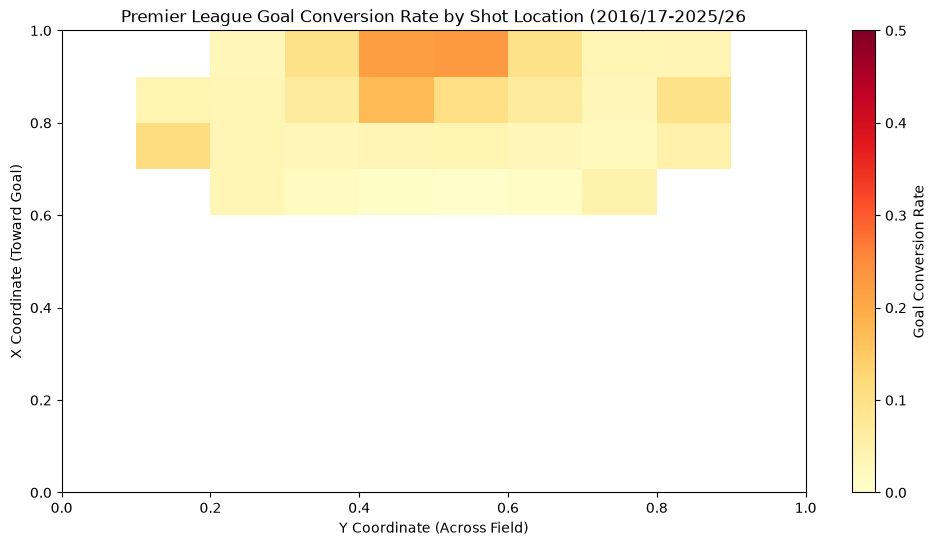

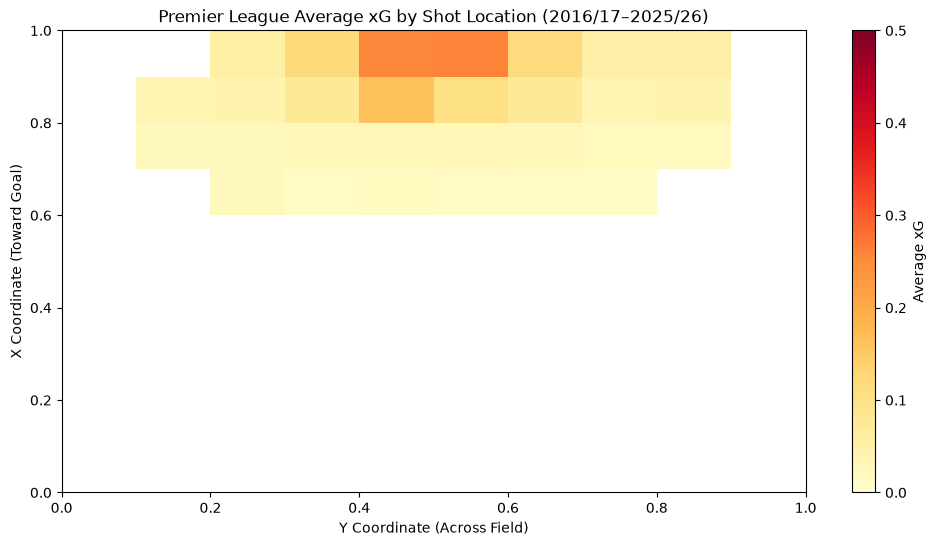

In [17]:
x_zones = shots["x_zone"].cat.categories
y_zones = shots["y_zone"].cat.categories

# Create grids using the correct categories
conversion_grid = zone_stats["conversion_rate"].unstack()
xg_grid = zone_stats["avg_xg"].unstack()
shot_count_grid = zone_stats["total_shots"].unstack()

# Reindex using the original interval categories
conversion_grid = conversion_grid.reindex(index=x_zones, columns=y_zones)
xg_grid = xg_grid.reindex(index=x_zones, columns=y_zones)

# Filter out zones with less than 30 shots
conversion_grid = conversion_grid.where(shot_count_grid >= 30)
xg_grid = xg_grid.where(shot_count_grid >= 30)


# Conversion rate heatmap
plt.figure(figsize=(12, 6))

plt.imshow(
    conversion_grid,
    origin="lower",
    cmap="YlOrRd",
    vmin=0,
    vmax=0.5,
    extent=[0, 1, 0, 1],
    aspect="auto"
)

plt.colorbar(label="Goal Conversion Rate")
plt.xlabel("Y Coordinate (Across Field)")
plt.ylabel("X Coordinate (Toward Goal)")
plt.title("Premier League Goal Conversion Rate by Shot Location (2016/17-2025/26")

plt.show()

# Average xG heatmap
plt.figure(figsize=(12, 6))

plt.imshow(
    xg_grid,
    origin="lower",
    cmap="YlOrRd",
    vmin=0,
    vmax=0.5,
    extent=[0, 1, 0, 1],
    aspect="auto"
)

plt.colorbar(label="Average xG")
plt.xlabel("Y Coordinate (Across Field)")
plt.ylabel("X Coordinate (Toward Goal)")
plt.title("Premier League Average xG by Shot Location (2016/17–2025/26)")

plt.show()

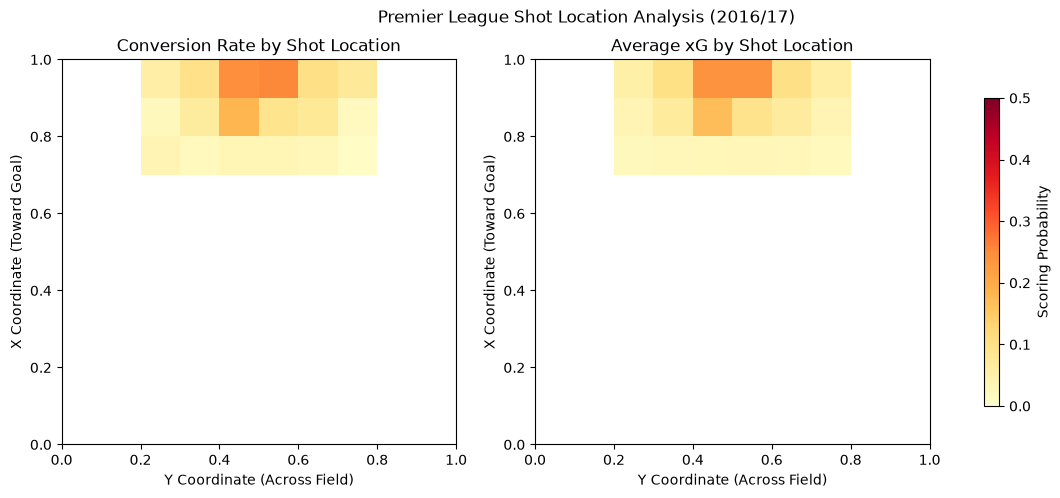

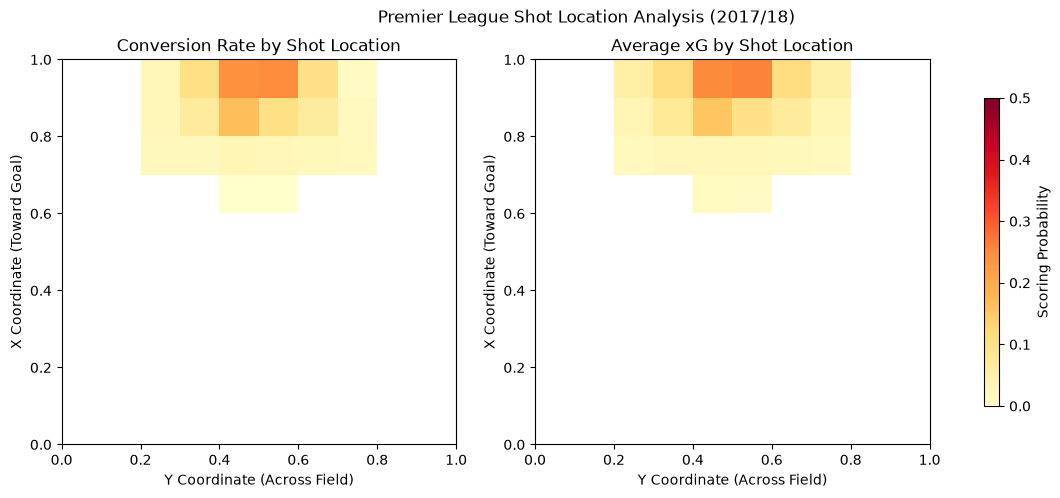

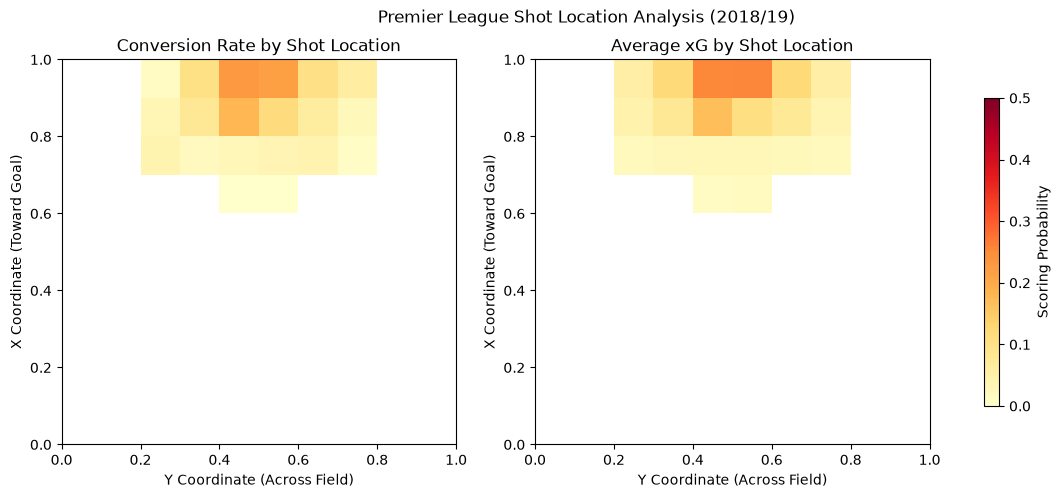

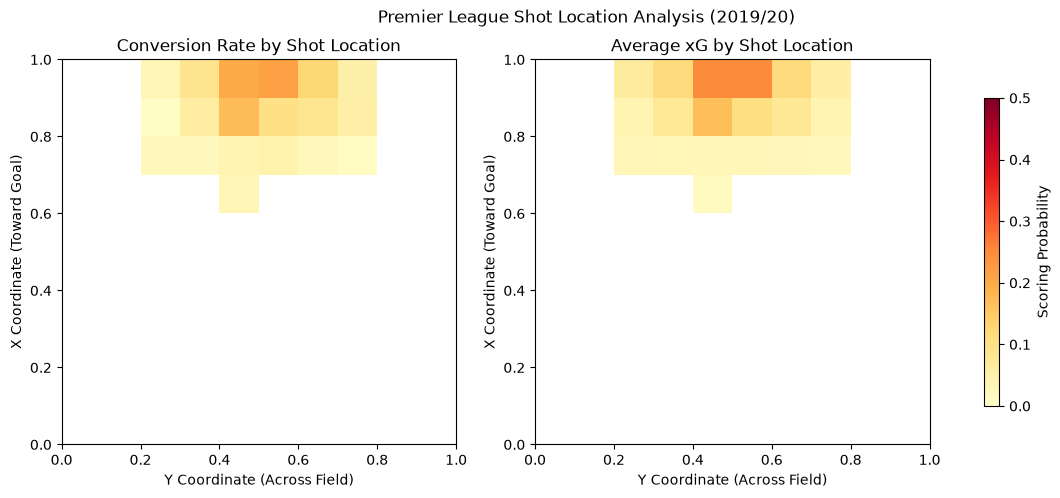

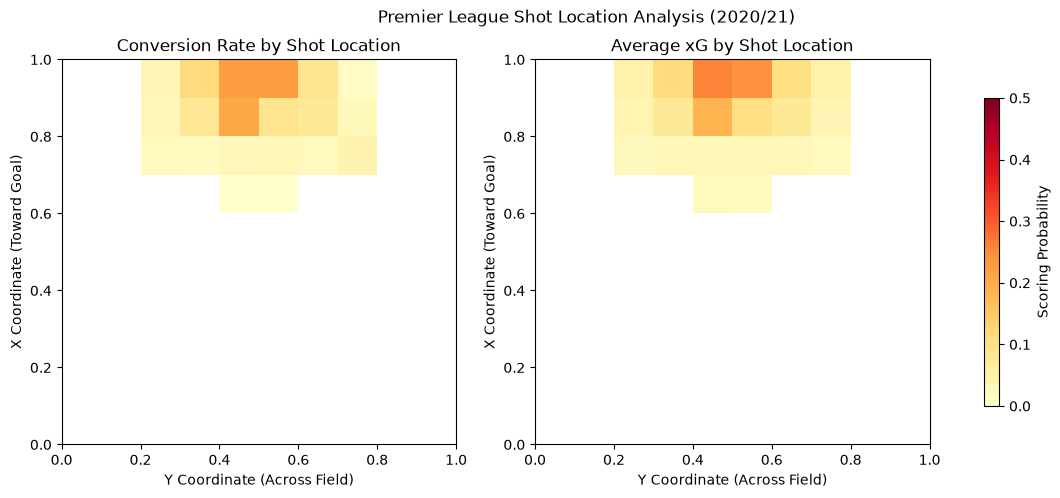

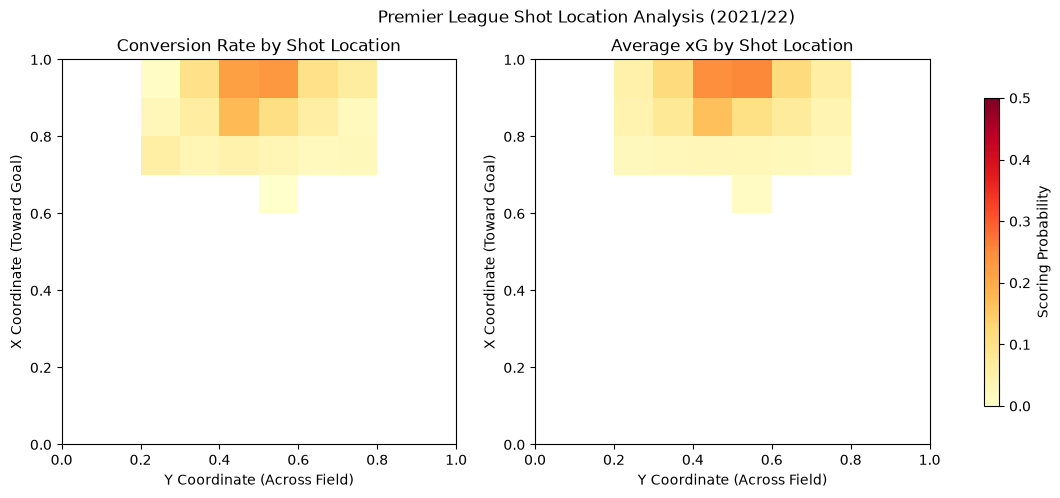

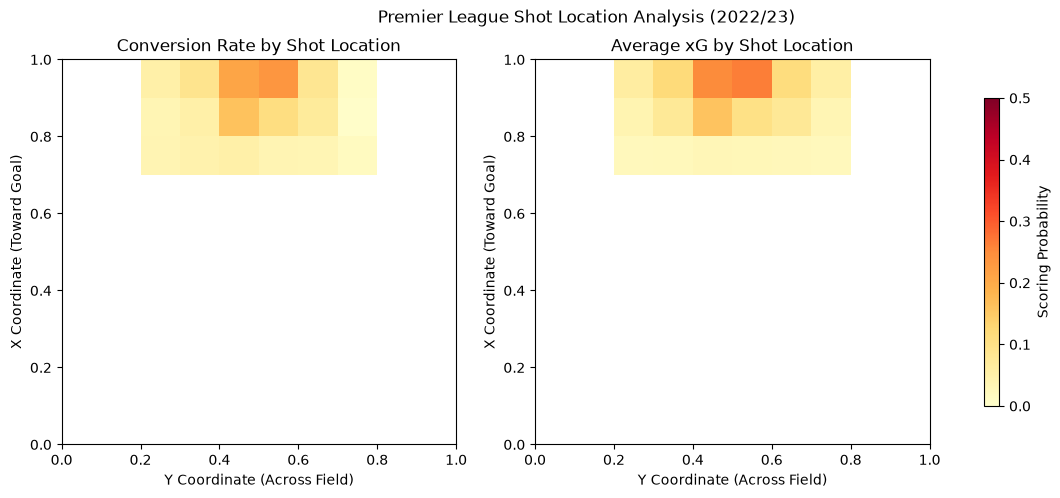

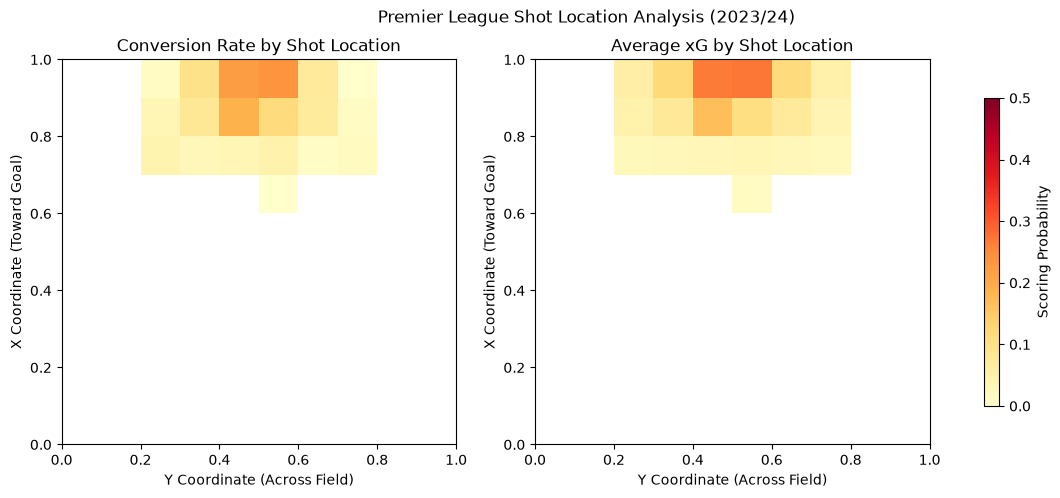

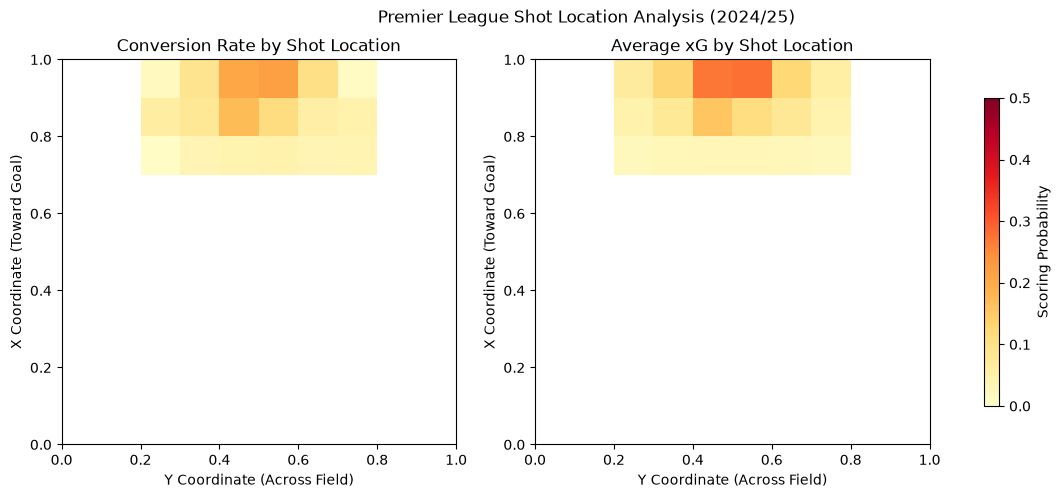

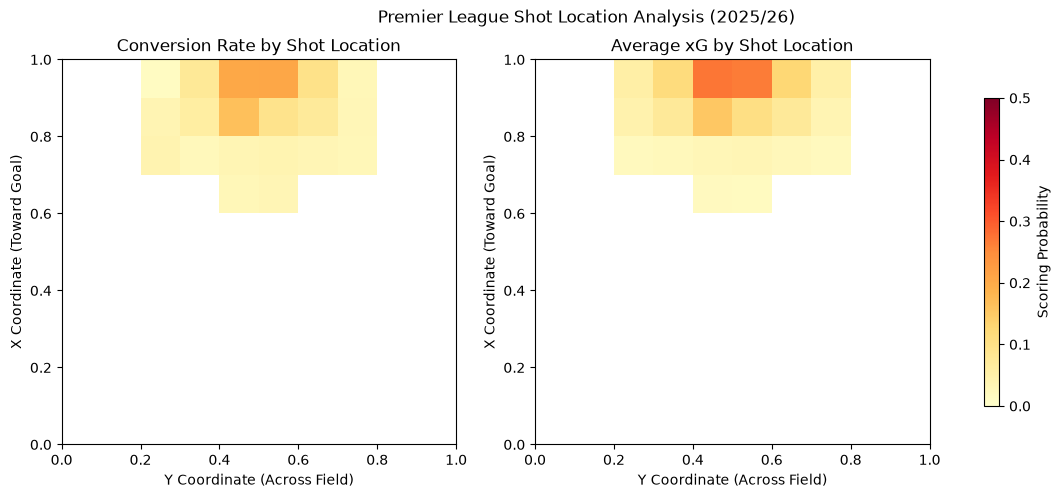

In [19]:
season_zone_stats = shots.groupby(
    ["season_id", "x_zone", "y_zone"],
    observed=True
).agg(
    total_shots=("is_goal", "count"),
    goals=("is_goal", "sum"),
    avg_xg=("xg", "mean")
)

season_zone_stats["conversion_rate"] = (
    season_zone_stats["goals"] / season_zone_stats["total_shots"]
)

for season in sorted(shots["season_id"].unique()):

    # Get statistics for this season
    season_data = season_zone_stats.loc[season]

    conversion_grid = season_data["conversion_rate"].unstack()
    xg_grid = season_data["avg_xg"].unstack()
    shot_count_grid = season_data["total_shots"].unstack()

    conversion_grid = conversion_grid.reindex(index=x_zones, columns=y_zones)
    xg_grid = xg_grid.reindex(index=x_zones, columns=y_zones)
    shot_count_grid = shot_count_grid.reindex(index=x_zones, columns=y_zones)

    # Filter out zones with less than 30 shots
    conversion_grid = conversion_grid.where(shot_count_grid >= 30)
    xg_grid = xg_grid.where(shot_count_grid >= 30)

    # Display two heatmaps side by side
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].imshow(
        conversion_grid,
        origin="lower",
        cmap="YlOrRd",
        vmin=0,
        vmax=0.5,
        extent=[0, 1, 0, 1],
        aspect="auto"
    )

    axes[0].set_title("Conversion Rate by Shot Location")
    axes[0].set_xlabel("Y Coordinate (Across Field)")
    axes[0].set_ylabel("X Coordinate (Toward Goal)")

    im = axes[1].imshow(
        xg_grid,
        origin="lower",
        cmap="YlOrRd",
        vmin=0,
        vmax=0.5,
        extent=[0, 1, 0, 1],
        aspect="auto"
    )

    axes[1].set_title("Average xG by Shot Location")
    axes[1].set_xlabel("Y Coordinate (Across Field)")
    axes[1].set_ylabel("X Coordinate (Toward Goal)")

    fig.colorbar(im, ax=axes, label="Scoring Probability", shrink=0.8)
    fig.suptitle(f"Premier League Shot Location Analysis ({season}/{str(season + 1)[-2:]})")

    plt.show()

# Question 2: Are teams that create more chances from open play more successful than set piece dependent teams?

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("epl_shots_2016_2025.csv")

print("Total shots:", len(df))
print("Seasons:", sorted(df["season_id"].unique()))
print("Teams:", df["team_id"].nunique())

display(df.head())

Total shots: 96715
Seasons: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Teams: 34


,league_id,season_id,game_id,date,shot_id,team_id,player_id,assist_player_id,assist_player,xg,location_x,location_y,minute,body_part,situation,result
0,1,2016,464,2016-08-13 18:00:00,112137,92,1660,1656.0,George Boyd,0.035097,0.897,0.249,31,Right Foot,Open Play,Missed Shot
1,1,2016,464,2016-08-13 18:00:00,112141,92,1660,NaN,NaN,0.097287,0.896,0.279,39,Right Foot,Open Play,Saved Shot
2,1,2016,464,2016-08-13 18:00:00,112151,92,1660,1652.0,Matthew Lowton,0.041747,0.897,0.274,73,Right Foot,Open Play,Missed Shot
3,1,2016,464,2016-08-13 18:00:00,112157,92,1660,1656.0,George Boyd,0.621750,0.958,0.534,83,Left Foot,Open Play,Missed Shot
4,1,2016,464,2016-08-13 18:00:00,112143,92,1658,1652.0,Matthew Lowton,0.016961,0.860,0.425,49,NaN,Open Play,Missed Shot


In [16]:
# Classify shot situations
df["shot_category"] = df["situation"].map({
    "Open Play": "Open Play",
    "From Corner": "Set Piece",
    "Set Piece": "Set Piece",
    "Direct Freekick": "Set Piece",
    "Penalty": "Set Piece"
})

# Missing situation values represent penalties in this dataset
df["shot_category"] = df["shot_category"].fillna("Set Piece")

# Identify goals and own goals
df["is_goal"] = (df["result"] == "Goal").astype(int)
df["is_own_goal"] = (df["result"] == "Own Goal").astype(int)

# Exclude own goals
shots = df[df["is_own_goal"] == 0].copy()

print(shots["shot_category"].value_counts())

shot_category
Open Play    70343
Set Piece    25999
Name: count, dtype: int64


In [17]:
category_stats = (
    shots.groupby("shot_category")
    .agg(
        Shots=("shot_id", "count"),
        Goals=("is_goal", "sum"),
        Total_xG=("xg", "sum"),
        Average_xG=("xg", "mean")
    )
    .reset_index()
)

category_stats["Conversion_Rate"] = (
    category_stats["Goals"] / category_stats["Shots"] * 100
)

category_stats["Average_xG"] *= 100

display(category_stats.round(2))

,shot_category,Shots,Goals,Total_xG,Average_xG,Conversion_Rate
0,Open Play,70343,7470,8059.43,11.46,10.62
1,Set Piece,25999,2930,3172.99,12.20,11.27


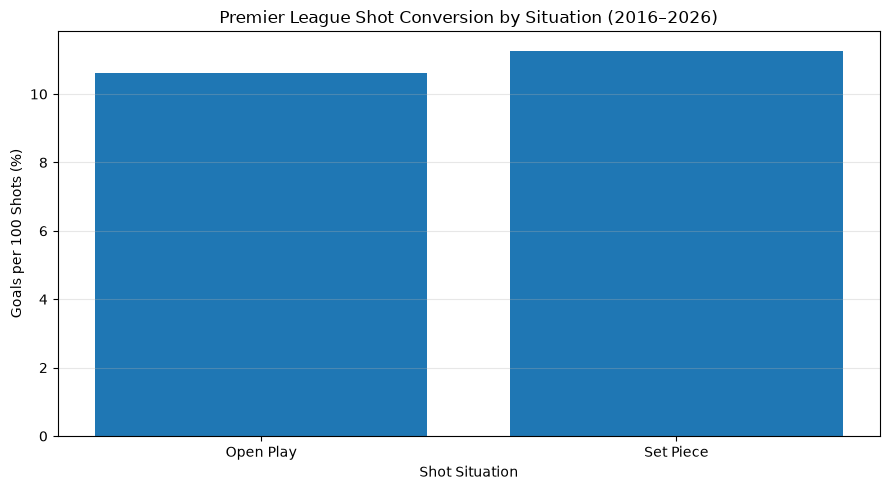

In [18]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_stats["shot_category"],
    category_stats["Conversion_Rate"]
)

plt.title("Premier League Shot Conversion by Situation (2016–2026)")
plt.xlabel("Shot Situation")
plt.ylabel("Goals per 100 Shots (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Focus on the two main categories
main_shots = shots[
    shots["shot_category"].isin(["Open Play", "Set Piece"])
].copy()

team_stats = (
    main_shots.groupby(
        ["season_id", "team_id", "shot_category"]
    )
    .agg(
        Shots=("shot_id", "count"),
        Goals=("is_goal", "sum"),
        xG=("xg", "sum")
    )
    .unstack(fill_value=0)
)

# Flatten the column names
team_stats.columns = [
    f"{metric}_{category.replace(' ', '_')}"
    for metric, category in team_stats.columns
]

team_stats = team_stats.reset_index()

team_stats["Total_Shots"] = (
    team_stats["Shots_Open_Play"] +
    team_stats["Shots_Set_Piece"]
)

team_stats["Set_Piece_Share"] = (
    team_stats["Shots_Set_Piece"] /
    team_stats["Total_Shots"] * 100
)

team_stats["Open_Play_Share"] = (
    team_stats["Shots_Open_Play"] /
    team_stats["Total_Shots"] * 100
)

team_stats["Set_Piece_Conversion"] = (
    team_stats["Goals_Set_Piece"] /
    team_stats["Shots_Set_Piece"].replace(0, np.nan) * 100
)

team_stats["Open_Play_Conversion"] = (
    team_stats["Goals_Open_Play"] /
    team_stats["Shots_Open_Play"].replace(0, np.nan) * 100
)

display(team_stats.head())

,season_id,team_id,Shots_Open_Play,Shots_Set_Piece,Goals_Open_Play,Goals_Set_Piece,xG_Open_Play,xG_Set_Piece,Total_Shots,Set_Piece_Share,Open_Play_Share,Set_Piece_Conversion,Open_Play_Conversion
0,2016,72,371,131,43,15,36.489940,13.375001,502,26.095618,73.904382,11.450382,11.590296
1,2016,73,329,124,35,18,34.105960,16.966589,453,27.373068,72.626932,14.516129,10.638298
2,2016,74,421,129,29,10,35.533830,14.777628,550,23.454545,76.545455,7.751938,6.888361
3,2016,75,302,131,34,12,29.062328,16.004921,433,30.254042,69.745958,9.160305,11.258278
4,2016,76,285,113,22,21,24.764587,13.981464,398,28.391960,71.608040,18.584071,7.719298


In [20]:
# Find the two teams in each match
match_teams = df[
    ["game_id", "season_id", "team_id"]
].drop_duplicates()

# Exclude games missing one team's shot records
match_teams = match_teams[
    match_teams.groupby("game_id")["team_id"]
    .transform("size").eq(2)
].copy()

# Identify each team's opponent
opponents = match_teams[["game_id", "team_id"]].merge(
    match_teams[["game_id", "team_id"]].rename(
        columns={"team_id": "opponent_id"}
    ),
    on="game_id"
)

opponents = opponents[
    opponents["team_id"] != opponents["opponent_id"]
]

# Count normal goals
normal_goals = (
    df[df["result"] == "Goal"]
    .groupby(["game_id", "team_id"])
    .size()
    .reset_index(name="normal_goals")
)

# Award own goals to the opposing team
own_goals = (
    df[df["result"] == "Own Goal"][
        ["game_id", "team_id"]
    ]
    .merge(opponents, on=["game_id", "team_id"])
    .groupby(["game_id", "opponent_id"])
    .size()
    .reset_index(name="own_goals_received")
    .rename(columns={"opponent_id": "team_id"})
)

# Reconstruct the scores
scores = (
    match_teams
    .merge(normal_goals, on=["game_id", "team_id"], how="left")
    .merge(own_goals, on=["game_id", "team_id"], how="left")
)

scores[["normal_goals", "own_goals_received"]] = (
    scores[["normal_goals", "own_goals_received"]].fillna(0)
)

scores["goals_for"] = (
    scores["normal_goals"] + scores["own_goals_received"]
)

# Attach opponent's goals
scores = scores.merge(
    scores[["game_id", "team_id", "goals_for"]].rename(
        columns={
            "team_id": "opponent_id",
            "goals_for": "goals_against"
        }
    ),
    on="game_id"
)

scores = scores[scores["team_id"] != scores["opponent_id"]]

# Calculate match points
scores["Points"] = np.select(
    [
        scores["goals_for"] > scores["goals_against"],
        scores["goals_for"] == scores["goals_against"]
    ],
    [3, 1],
    default=0
)

# Calculate points earned by each team each season
team_points = (
    scores.groupby(["season_id", "team_id"])
    .agg(
        Matches=("game_id", "nunique"),
        Points=("Points", "sum")
    )
    .reset_index()
)

team_points["Points_Per_Game"] = (
    team_points["Points"] / team_points["Matches"]
)

# Combine team performance with shot statistics
team_stats = team_stats.merge(
    team_points,
    on=["season_id", "team_id"],
    how="inner"
)

display(team_stats.head())

,season_id,team_id,Shots_Open_Play,Shots_Set_Piece,Goals_Open_Play,Goals_Set_Piece,xG_Open_Play,xG_Set_Piece,Total_Shots,Set_Piece_Share,Open_Play_Share,Set_Piece_Conversion,Open_Play_Conversion,Matches,Points,Points_Per_Game
0,2016,72,371,131,43,15,36.489940,13.375001,502,26.095618,73.904382,11.450382,11.590296,38,61,1.605263
1,2016,73,329,124,35,18,34.105960,16.966589,453,27.373068,72.626932,14.516129,10.638298,38,46,1.210526
2,2016,74,421,129,29,10,35.533830,14.777628,550,23.454545,76.545455,7.751938,6.888361,38,46,1.210526
3,2016,75,302,131,34,12,29.062328,16.004921,433,30.254042,69.745958,9.160305,11.258278,38,44,1.157895
4,2016,76,285,113,22,21,24.764587,13.981464,398,28.391960,71.608040,18.584071,7.719298,38,45,1.184211


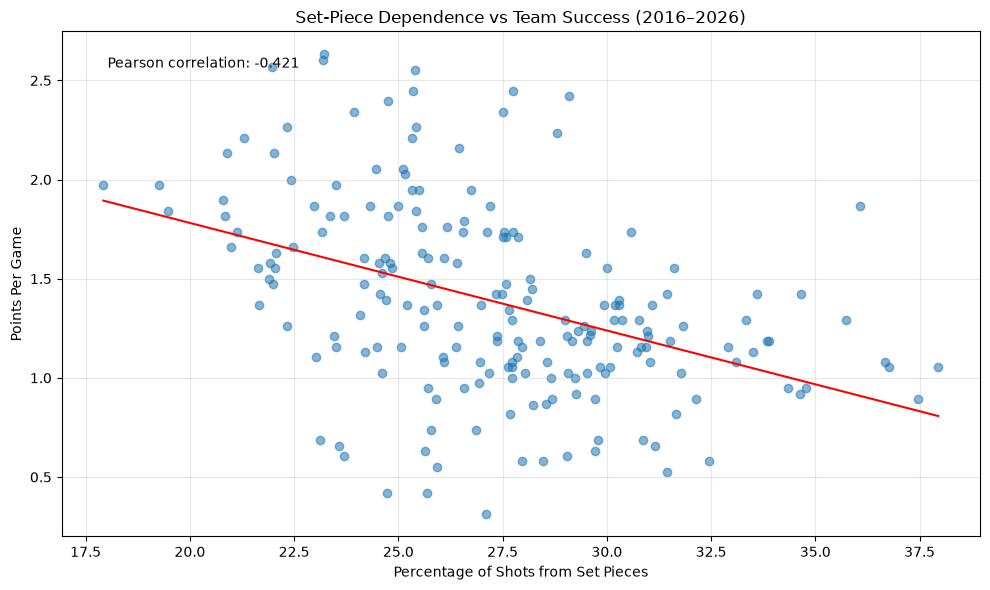

Correlation: -0.421


In [21]:
plt.figure(figsize=(10, 6))

plt.scatter(
    team_stats["Set_Piece_Share"],
    team_stats["Points_Per_Game"],
    alpha=0.55
)

# Calculate correlation
correlation = team_stats[
    ["Set_Piece_Share", "Points_Per_Game"]
].corr().iloc[0, 1]

# Add trend line
x = team_stats["Set_Piece_Share"]
y = team_stats["Points_Per_Game"]

slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
plt.plot(x_line, slope * x_line + intercept, color="red")

plt.title("Set-Piece Dependence vs Team Success (2016–2026)")
plt.xlabel("Percentage of Shots from Set Pieces")
plt.ylabel("Points Per Game")

plt.text(
    0.05, 0.95,
    f"Pearson correlation: {correlation:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Correlation:", round(correlation, 3))

In [22]:
median_share = team_stats["Set_Piece_Share"].median()

team_stats["Playstyle"] = np.where(
    team_stats["Set_Piece_Share"] >= median_share,
    "More Set-Piece Dependent",
    "More Open-Play Dependent"
)

playstyle_results = (
    team_stats.groupby("Playstyle")
    .agg(
        Teams_Seasons=("team_id", "count"),
        Avg_Points_Per_Game=("Points_Per_Game", "mean"),
        Avg_Open_Play_Goals=("Goals_Open_Play", "mean"),
        Avg_Set_Piece_Goals=("Goals_Set_Piece", "mean"),
        Avg_Set_Piece_Share=("Set_Piece_Share", "mean")
    )
)

display(playstyle_results.round(2))

,Teams_Seasons,Avg_Points_Per_Game,Avg_Open_Play_Goals,Avg_Set_Piece_Goals,Avg_Set_Piece_Share
Playstyle,,,,,
More Open-Play Dependent,100,1.56,43.98,14.49,24.36
More Set-Piece Dependent,100,1.21,30.72,14.81,30.29


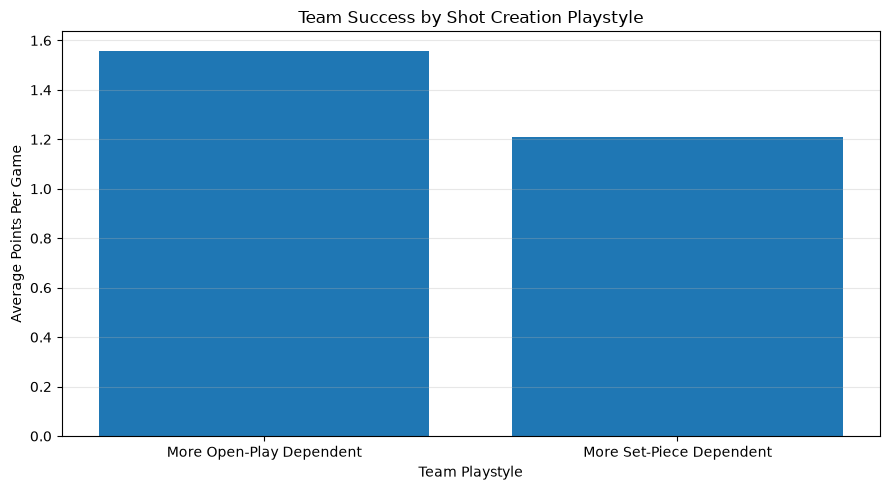

In [23]:
plt.figure(figsize=(9, 5))

plt.bar(
    playstyle_results.index,
    playstyle_results["Avg_Points_Per_Game"]
)

plt.title("Team Success by Shot Creation Playstyle")
plt.xlabel("Team Playstyle")
plt.ylabel("Average Points Per Game")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


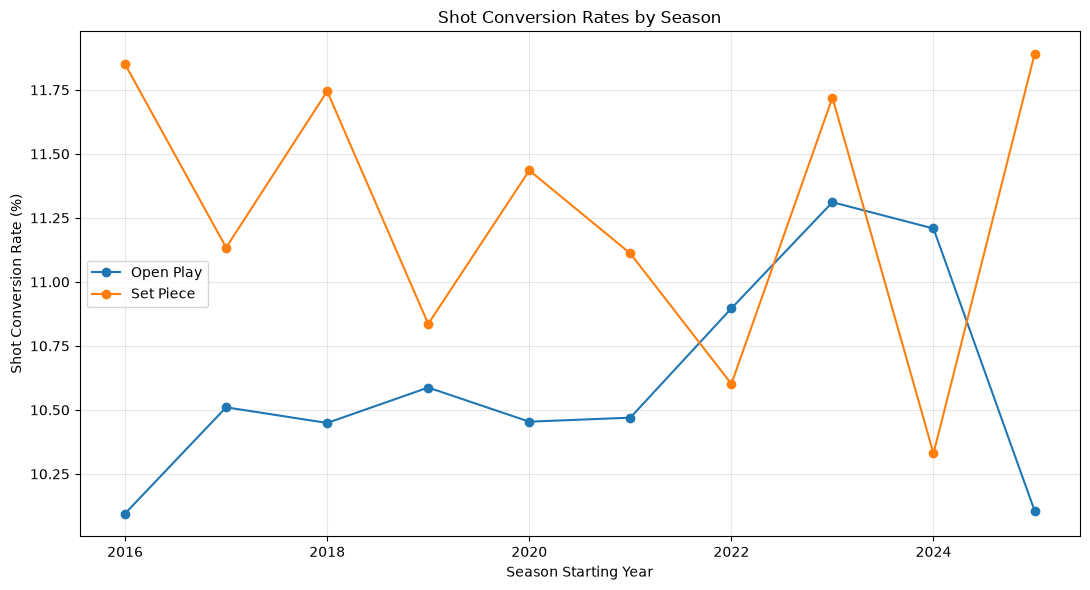

In [24]:
season_trends = (
    main_shots.groupby(["season_id", "shot_category"])
    .agg(
        Shots=("shot_id", "count"),
        Goals=("is_goal", "sum"),
        xG=("xg", "sum")
    )
    .reset_index()
)

season_trends["Conversion_Rate"] = (
    season_trends["Goals"] /
    season_trends["Shots"] * 100
)

# Compare shot conversion rates over time
conversion_trends = season_trends.pivot(
    index="season_id",
    columns="shot_category",
    values="Conversion_Rate"
)

plt.figure(figsize=(11, 6))

for category in conversion_trends.columns:
    plt.plot(
        conversion_trends.index,
        conversion_trends[category],
        marker="o",
        label=category
    )

plt.title("Shot Conversion Rates by Season")
plt.xlabel("Season Starting Year")
plt.ylabel("Shot Conversion Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

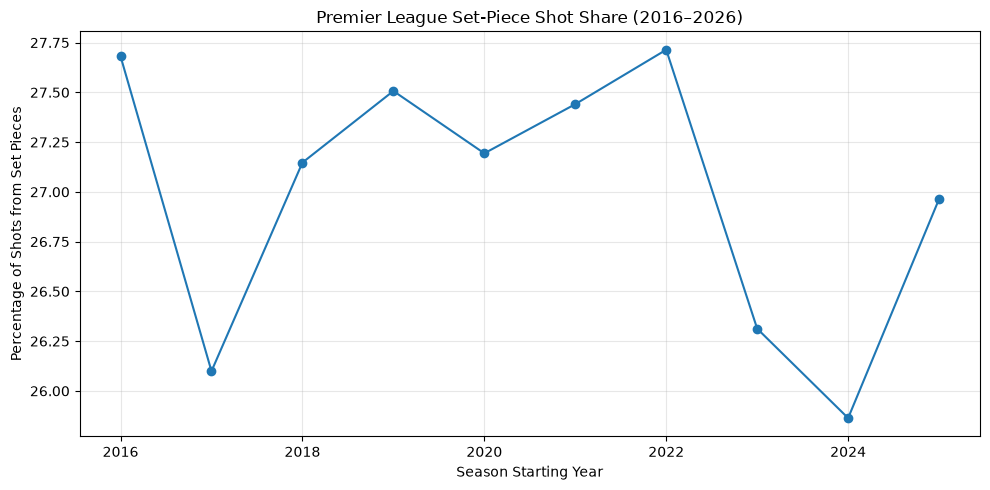

shot_category,Open Play,Set Piece,Set_Piece_Percentage
season_id,,,
2016,7033,2692,27.68
2017,6841,2416,26.10
2018,7015,2614,27.15
2019,6810,2584,27.51
2020,6696,2501,27.19
2021,7068,2673,27.44
2022,6938,2660,27.71
2023,7718,2756,26.31
2024,7298,2546,25.86


In [25]:
season_shares = (
    main_shots.groupby(["season_id", "shot_category"])
    .size()
    .unstack(fill_value=0)
)

season_shares["Set_Piece_Percentage"] = (
    season_shares["Set Piece"] /
    (season_shares["Open Play"] + season_shares["Set Piece"]) * 100
)

plt.figure(figsize=(10, 5))

plt.plot(
    season_shares.index,
    season_shares["Set_Piece_Percentage"],
    marker="o"
)

plt.title("Premier League Set-Piece Shot Share (2016–2026)")
plt.xlabel("Season Starting Year")
plt.ylabel("Percentage of Shots from Set Pieces")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(season_shares.round(2))

In [26]:
from scipy.stats import ttest_ind

set_piece_teams = team_stats[
    team_stats["Playstyle"] == "More Set-Piece Dependent"
]["Points_Per_Game"]

open_play_teams = team_stats[
    team_stats["Playstyle"] == "More Open-Play Dependent"
]["Points_Per_Game"]

t_stat, p_value = ttest_ind(
    set_piece_teams,
    open_play_teams,
    equal_var=False
)

print("Set-piece group average PPG:", round(set_piece_teams.mean(), 3))
print("Open-play group average PPG:", round(open_play_teams.mean(), 3))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Statistically significant difference at alpha = 0.05")
else:
    print("No statistically significant difference at alpha = 0.05")

Set-piece group average PPG: 1.209
Open-play group average PPG: 1.559
T-statistic: -5.4966
P-value: 0.0
Statistically significant difference at alpha = 0.05


In [27]:
print("PREMIER LEAGUE SHOT ANALYSIS")
print("2016-17 through 2025-26")
print("-" * 45)

print("\nShot conversion rates:")
display(category_stats[
    ["shot_category", "Shots", "Goals", "Conversion_Rate"]
].round(2))

print("\nPlaystyle comparison:")
display(playstyle_results.round(2))

print("\nSet-piece dependence vs points per game:")
print(f"Pearson correlation: {correlation:.3f}")

print("\nStatistical comparison:")
print(f"P-value: {p_value:.4f}")

print("\nSet-piece shot share by season:")
display(season_shares[["Set_Piece_Percentage"]].round(2))

PREMIER LEAGUE SHOT ANALYSIS
2016-17 through 2025-26
---------------------------------------------

Shot conversion rates:


,shot_category,Shots,Goals,Conversion_Rate
0,Open Play,70343,7470,10.62
1,Set Piece,25999,2930,11.27



Playstyle comparison:


,Teams_Seasons,Avg_Points_Per_Game,Avg_Open_Play_Goals,Avg_Set_Piece_Goals,Avg_Set_Piece_Share
Playstyle,,,,,
More Open-Play Dependent,100,1.56,43.98,14.49,24.36
More Set-Piece Dependent,100,1.21,30.72,14.81,30.29



Set-piece dependence vs points per game:
Pearson correlation: -0.421

Statistical comparison:
P-value: 0.0000

Set-piece shot share by season:


shot_category,Set_Piece_Percentage
season_id,
2016,27.68
2017,26.10
2018,27.15
2019,27.51
2020,27.19
2021,27.44
2022,27.71
2023,26.31
2024,25.86


# Premier League: Which teams have the largest differences in actual points and expected points?

In [ ]:
matchdf = pd.read_csv("epl_shots_2016_2025.csv");

# Preprocessing to help parse 'Own Goals'
matchdf["is_goal"] = (matchdf["result"] == "Goal").astype(int)
matchdf["is_own_goal"] = (matchdf["result"] == "Own Goal").astype(int)
matchdf["xg_valid"] = matchdf["xg"].where(matchdf["result"] != "Own Goal", 0)

# One Row per Team per Match
teamGames = (matchdf.groupby(["season_id", "game_id", "team_id"], as_index=False)
            .agg(xg_for=("xg_valid", "sum"),
                 goals_scored=("is_goal", "sum"),
                 own_goals_by=("is_own_goal", "sum")))

# Gather stats from single games
singleGame = teamGames.groupby(["season_id", "game_id"])
# Expected goals by team in season
xgTotal = singleGame["xg_for"].transform("sum")
# Own goals by team in season
ownGoalsTotal = singleGame["own_goals_by"].transform("sum")
# Goals scored by team in season
goalsTotal = singleGame["goals_scored"].transform("sum") + ownGoalsTotal

teamGames["goals_for"] = teamGames["goals_scored"] + (ownGoalsTotal - teamGames["own_goals_by"])
teamGames["goals_against"] = goalsTotal - teamGames["goals_for"]
teamGames["xg_against"] = xgTotal - teamGames["xg_for"]

seasonTable = (teamGames.groupby(["season_id", "team_id"], as_index=False)
            .agg(matches=("game_id", "count"),
            goals_for=("goals_for", "sum"), xg_for=("xg_for", "sum"),
            goals_against=("goals_against", "sum"), xg_against=("xg_against", "sum")))
# How team scored vs expectation
# Main component of research question
seasonTable["gf_diff"] = seasonTable["goals_for"] - seasonTable["xg_for"]
# How team fared defending vs expectation
seasonTable["ga_diff"] = seasonTable["goals_against"] - seasonTable["xg_against"]
# How team was expected to score against opponent
seasonTable["xg_diff"] = seasonTable["xg_for"] - seasonTable["xg_against"]


print("Biggest single season finishing overperformers (goals above xG):")
print(seasonTable.sort_values("gf_diff", ascending=False).head(10).round(1))

print("\nBiggest single season finishing underperformers (goals below xG):")
print(seasonTable.sort_values("gf_diff").head(10).round(1))


Biggest single season finishing overperformers (goals above xG):
     season_id  team_id  matches  goals_for  xg_for  goals_against  \
7         2016       80       38         85    62.4             33   
9         2016       82       38         86    71.0             26   
34        2017       88       38        106    93.2             27   
0         2016       72       38         62    49.9             44   
10        2016       83       38         77    65.0             44   
128       2022       82       38         70    58.4             63   
103       2021       75       38         62    50.4             59   
69        2019       82       38         61    50.3             47   
129       2022       83       38         88    77.4             43   
13        2016       87       38         78    67.4             42   

     xg_against  gf_diff  ga_diff  xg_diff  
7          28.7     22.6      4.3     33.7  
9          34.3     15.0     -8.3     36.8  
34         24.9     12.8     

In [ ]:
#TODO: PLOTS